# UTS Pembelajaran Mesin — SOAL 3 


### 3.1 Import library & konfigurasi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

FILE = "KPIP_Dimensi_Output_2025.xlsx"
AMBANG = 78.19          # rata-rata nasional Informasi Terpercaya -> batas kelas Tinggi
FITUR = ["prinsip", "pelibatan"]
sns.set_theme(style="whitegrid")

### 3.2 Load data & pembersihan struktur (header 2 baris, baris NASIONAL)

In [2]:
df = pd.read_excel(FILE, header=None, skiprows=2)
df.columns = ["kode", "provinsi", "prinsip", "pelibatan", "info", "output"]
print("Ukuran mentah:", df.shape)
df = df[df["kode"].astype(str) != "NASIONAL"].copy()     # buang baris rata-rata nasional
for k in ["prinsip", "pelibatan", "info", "output"]:
    df[k] = pd.to_numeric(df[k])
df = df.reset_index(drop=True)
print("Setelah dibersihkan:", df.shape)
display(df.head())
df.info()

Ukuran mentah: (39, 6)
Setelah dibersihkan: (38, 6)


,kode,provinsi,prinsip,pelibatan,info,output
0,11,Aceh,71.54,63.65,69.26,68.15
1,12,Sumatera Utara,77.87,69.78,77.78,75.14
2,13,Sumatera Barat,77.90,69.25,76.17,74.44
3,14,Riau,86.45,85.45,90.18,87.36
4,15,Jambi,75.86,71.25,73.70,73.60


<class 'pandas.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   kode       38 non-null     object 
 1   provinsi   38 non-null     str    
 2   prinsip    38 non-null     float64
 3   pelibatan  38 non-null     float64
 4   info       38 non-null     float64
 5   output     38 non-null     float64
dtypes: float64(4), object(1), str(1)
memory usage: 1.9+ KB


### 3.3 EDA

In [3]:
print("Missing value per kolom:\n", df.isnull().sum(), "\n")
display(df[["prinsip", "pelibatan", "info", "output"]].describe().round(2))
print("Duplikat baris:", df.duplicated().sum())

Missing value per kolom:
 kode         0
provinsi     0
prinsip      0
pelibatan    0
info         0
output       0
dtype: int64 



,prinsip,pelibatan,info,output
count,38.00,38.00,38.00,38.00
mean,77.78,70.85,78.19,75.60
std,5.21,7.51,6.95,5.92
min,67.65,60.41,66.67,65.74
25%,73.63,64.75,71.74,71.78
50%,78.53,69.82,77.96,74.94
75%,81.63,76.35,83.63,79.87
max,88.25,89.09,92.04,89.79


Duplikat baris: 0


In [4]:
def batas_iqr(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

for k in ["prinsip", "pelibatan", "info"]:
    lo, hi = batas_iqr(df[k])
    n_out = ((df[k] < lo) | (df[k] > hi)).sum()
    print(f"{k:10s} batas [{lo:.2f}, {hi:.2f}] -> outlier: {n_out}")

prinsip    batas [61.63, 93.63] -> outlier: 0
pelibatan  batas [47.34, 93.76] -> outlier: 0
info       batas [53.89, 101.48] -> outlier: 0


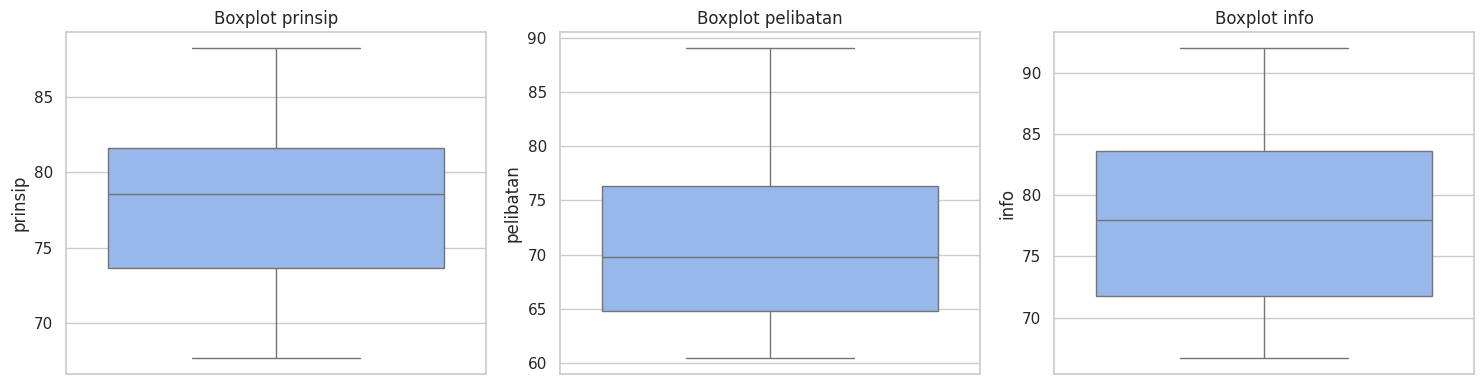

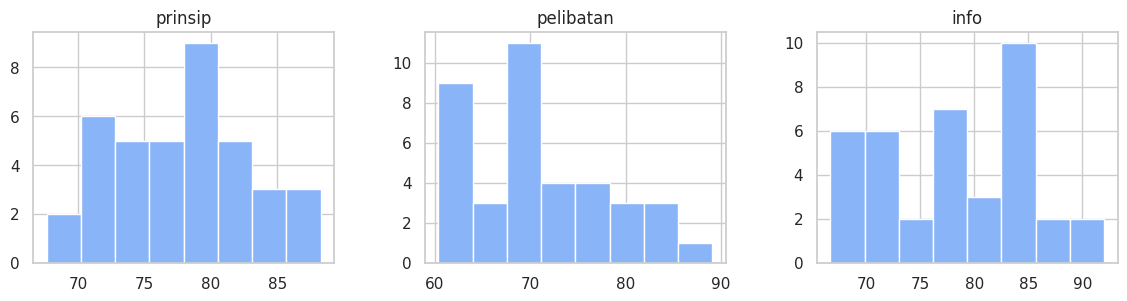

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, k in zip(ax, ["prinsip", "pelibatan", "info"]):
    sns.boxplot(y=df[k], ax=a, color="#8ab4f8"); a.set_title(f"Boxplot {k}")
plt.tight_layout(); plt.show()

df[["prinsip", "pelibatan", "info"]].hist(bins=8, figsize=(14, 3), layout=(1, 3), color="#8ab4f8", edgecolor="white")
plt.show()

### 3.4 Pembuatan label target & korelasi

kelas
Rendah    20
Tinggi    18
Name: count, dtype: int64

Maks selisih output vs rata-rata 3 sub-indikator: 0.003


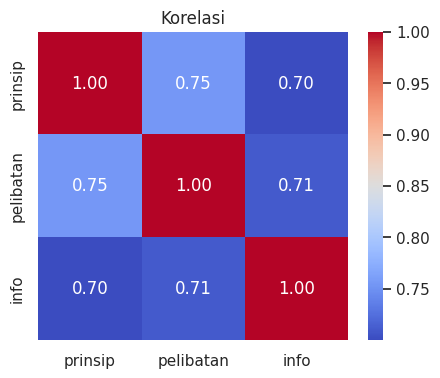

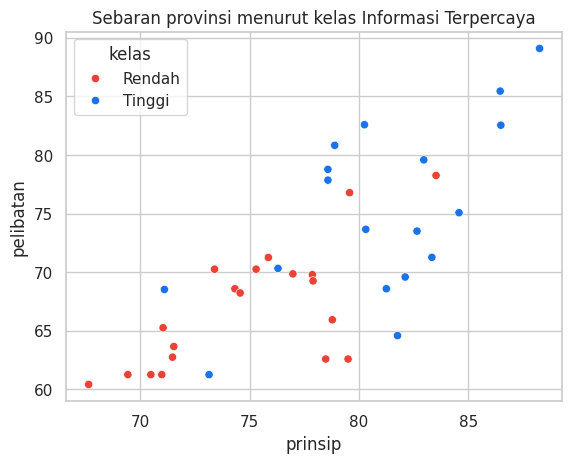

In [6]:
df["kelas"] = np.where(df["info"] >= AMBANG, "Tinggi", "Rendah")
df["y"] = (df["kelas"] == "Tinggi").astype(int)
print(df["kelas"].value_counts())

# bukti kebocoran: output = rata-rata tiga sub-indikator
print("\nMaks selisih output vs rata-rata 3 sub-indikator:",
      (df["output"] - df[["prinsip", "pelibatan", "info"]].mean(axis=1)).abs().max().round(3))

plt.figure(figsize=(5, 4))
sns.heatmap(df[["prinsip", "pelibatan", "info"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi"); plt.show()

sns.scatterplot(data=df, x="prinsip", y="pelibatan", hue="kelas", palette={"Tinggi": "#1a73e8", "Rendah": "#ea4335"})
plt.title("Sebaran provinsi menurut kelas Informasi Terpercaya"); plt.show()

### 3.5 Pembuatan model KNN
Imputasi, penanganan outlier (capping IQR), dan normalisasi dimasukkan ke dalam `Pipeline` supaya dipelajari dari data latih saja (tanpa *data leakage*). Pada data ini imputasi dan capping tidak mengubah apa-apa karena memang tidak ada missing value/outlier, tetapi langkahnya tetap aman bila data berubah.

In [7]:
X, y = df[FITUR], df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

class CapIQR(FunctionTransformer):
    pass

def fit_cap(X):
    X = pd.DataFrame(X).copy()
    for col in X.columns:
        lo, hi = batas_iqr(X[col]); X[col] = X[col].clip(lo, hi)
    return X.values

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("cap",     FunctionTransformer(fit_cap)),
    ("scaler",  MinMaxScaler()),
    ("knn",     KNeighborsClassifier(metric="euclidean")),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, {"knn__n_neighbors": [1, 3, 5, 7, 9]}, cv=cv, scoring="accuracy")
grid.fit(X_train, y_train)
print("K terbaik:", grid.best_params_["knn__n_neighbors"], "| akurasi CV:", round(grid.best_score_, 3))
model = grid.best_estimator_

Data latih: (28, 2) | Data uji: (10, 2)
K terbaik: 3 | akurasi CV: 0.82


### 3.6 Evaluasi model

Akurasi : 1.0
Presisi : 1.0
Recall  : 1.0
F1-score: 1.0

              precision    recall  f1-score   support

      Rendah       1.00      1.00      1.00         5
      Tinggi       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



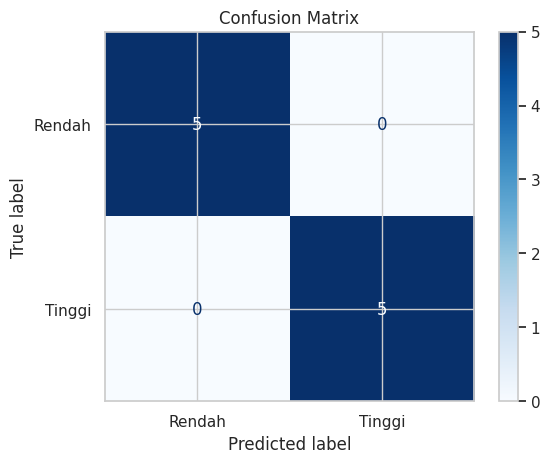

Akurasi cross-validation 5-fold: [1.    0.875 0.75  0.857 0.714] | rata-rata: 0.839


In [8]:
y_pred = model.predict(X_test)
print("Akurasi :", round(accuracy_score(y_test, y_pred), 3))
print("Presisi :", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall  :", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print()
print(classification_report(y_test, y_pred, target_names=["Rendah", "Tinggi"], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Rendah", "Tinggi"]).plot(cmap="Blues")
plt.title("Confusion Matrix"); plt.show()

skor = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=7), scoring="accuracy")
print("Akurasi cross-validation 5-fold:", skor.round(3), "| rata-rata:", skor.mean().round(3))

### 3.7 Verifikasi dengan hitungan manual Soal 2 (15 data latih, K=3, uji: Sulawesi Utara)

In [9]:
nama_latih = ["Riau", "Lampung", "Jawa Tengah", "Nusa Tenggara Timur", "Kalimantan Tengah", "Sulawesi Selatan", "Maluku",
              "Aceh", "Sumatera Utara", "Jambi", "Bengkulu", "DKI Jakarta", "Jawa Timur", "Banten", "Bali"]
lat = df[df["provinsi"].isin(nama_latih)]
uji = df[df["provinsi"] == "Sulawesi Utara"]

m = Pipeline([("scaler", MinMaxScaler()), ("knn", KNeighborsClassifier(n_neighbors=3))]).fit(lat[FITUR], lat["y"])
p = m.predict(uji[FITUR])[0]
print("Prediksi kode  :", "Tinggi" if p == 1 else "Rendah")
print("Hitungan manual: Rendah")
print("Kelas sebenarnya:", uji["kelas"].iloc[0])

Prediksi kode  : Rendah
Hitungan manual: Rendah
Kelas sebenarnya: Tinggi
